# HD2Lab · 심화 머신러닝 실험

7개 장의 21개 심화 사례와 28개 비교 그림. 모든 데이터는 합성입니다. NumPy와 Matplotlib이 필요합니다. 위에서 아래로 실행하면 표의 수치와 그림을 다시 계산합니다. 저장된 출력도 같은 코드로 계산한 스냅샷입니다. 기본 실험실의 데이터와는 다른 실험입니다.

각 함수의 생성식·시드·정규화와 웹 본문의 가정을 함께 확인하세요. 숫자는 라이브러리 버전에 따라 마지막 자릿수가 달라질 수 있습니다.

## 공통 계산 함수
NumPy만 사용하는 회귀, EM, 쌍대 SVM과 장별 데이터 생성 함수입니다.

In [1]:
#!/usr/bin/env python3
"""HD2Lab 심화 실험: NumPy만으로 실행. 모든 관측은 합성 데이터.
python advanced-experiments.py --chapter 2
python advanced-experiments.py --output-json results.json
함수별 반환 배열로 표와 그림을 재현한다. 시드는 장마다 고정한다.
"""
import argparse
import json
import math
from pathlib import Path
import numpy as np


def mse(y, prediction):
    return float(np.mean((y - prediction) ** 2))


def ridge(X, y, alpha):
    # 잔차 제곱합 + alpha * ||기울기||². 첫 열은 절편.
    penalty = np.eye(X.shape[1])[1:] * np.sqrt(alpha)
    return np.linalg.lstsq(np.vstack([X, penalty]),
                           np.r_[y, np.zeros(len(penalty))], rcond=None)[0]


def data_experiment():
    rng = np.random.default_rng(2101)
    hour = np.arange(200) % 24
    t = np.arange(200)
    signal = 30 + 8 * np.sin(2 * np.pi * hour / 24)
    y = signal + 6 * (t >= 140) + rng.normal(0, 1.5, 200)
    X = np.c_[np.ones(200), np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24)]
    raw = np.c_[np.ones(200), hour]
    train, valid, test = np.arange(120), np.arange(120,160), np.arange(160,200)
    cycle = X @ ridge(X[train], y[train], 0)
    linear = raw @ ridge(raw[train], y[train], 0)
    # 의도적으로 금지된 비교: 타깃이 이미 들어 있는 특징.
    leaked = np.c_[X, y + rng.normal(0, .02, 200)]
    oracle = leaked @ ridge(leaked[train], y[train], 0)
    shuffled = rng.permutation(160)
    random_train, random_valid = shuffled[:120], shuffled[120:]
    random_pred = X @ ridge(X[random_train], y[random_train], 0)
    labels = np.r_[np.ones(200, dtype=int), np.zeros(9800, dtype=int)]
    scores = 2 * labels + rng.normal(size=10000)
    thresholds = np.linspace(-1, 4, 101)
    rows = []
    for threshold in thresholds:
        positive = scores >= threshold
        tp = int(np.sum(positive & (labels == 1)))
        fp = int(np.sum(positive & (labels == 0)))
        fn = 200 - tp
        rows.append([threshold, tp, fp, fn, 9800-fp,
                     tp/max(1,tp+fp), tp/200, (tp+9800-fp)/10000, 25*fn+fp])
    rows = np.array(rows)
    return dict(hour=hour,t=t,y=y,signal=signal,X=X,cycle=cycle,linear=linear,
                thresholds=rows, scores=scores, labels=labels,
                summary=dict(cycle_valid=mse(y[valid],cycle[valid]),
                             raw_valid=mse(y[valid],linear[valid]),
                             random_valid=mse(y[random_valid],random_pred[random_valid]),
                             cycle_test=mse(y[test],cycle[test]),
                             leaked_valid=mse(y[valid],oracle[valid]),
                             threshold_rows=rows[[30,50,70]].tolist(),
                             best_threshold=float(rows[np.argmin(rows[:,-1]),0])))


def regression_experiment():
    rng = np.random.default_rng(2202)
    x = rng.normal(size=70)
    X = np.c_[np.ones(70), x, x + .015*rng.normal(size=70)]
    y = 1 + 2*x + rng.normal(0,.4,70)
    alphas = np.logspace(-5,2,60)
    path = np.array([ridge(X,y,a) for a in alphas])
    perturb = np.array([[ridge(X,y+rng.normal(0,.05,70),a) for a in [0,1]] for _ in range(120)])
    singular = np.linalg.svd(X[:,1:] - X[:,1:].mean(0),compute_uv=False)
    xp = rng.uniform(-1,1,30)
    truth = lambda v: 1 + 1.8*v - 2*v*v + 2.5*v**3
    yp = truth(xp) + rng.normal(0,.45,30)
    xv = rng.uniform(-1,1,240); yv = truth(xv)+rng.normal(0,.45,240)
    degrees = np.arange(1,10); grid_alpha = np.array([0, .0001,.01,.1,1,10])
    errors = np.array([[mse(yv,np.polynomial.polynomial.polyvander(xv,d) @
                    ridge(np.polynomial.polynomial.polyvander(xp,d),yp,a))
                    for a in grid_alpha] for d in degrees])
    di, ai = np.unravel_index(errors.argmin(), errors.shape)
    degree, alpha = int(degrees[di]), float(grid_alpha[ai])
    xt = rng.uniform(-1,1,400); yt = truth(xt)+rng.normal(0,.45,400)
    final_w = ridge(np.polynomial.polynomial.polyvander(xp,degree),yp,alpha)
    test_mse = mse(yt,np.polynomial.polynomial.polyvander(xt,degree)@final_w)
    grid = np.linspace(-1.35,1.35,250)
    fits = {str(d): np.polynomial.polynomial.polyvander(grid,d)@
            ridge(np.polynomial.polynomial.polyvander(xp,d),yp,0) for d in [1,3,9]}
    design = np.polynomial.polynomial.polyvander(xp,degree)
    basis = np.polynomial.polynomial.polyvander(grid,degree)
    boot = []
    for _ in range(350):
        ids = rng.integers(0,len(xp),len(xp))
        boot.append(basis@ridge(design[ids],yp[ids],alpha))
    boot=np.array(boot)
    # 잡음 표준편차 .45가 알려진 이 합성 문제에서만 가능한 예측 draw.
    predictive = boot + rng.normal(0,.45,boot.shape)
    return dict(alphas=alphas,path=path,perturb=perturb,singular=singular,
                xp=xp,yp=yp,grid=grid,truth=truth(grid),fits=fits,
                degrees=degrees,grid_alpha=grid_alpha,errors=errors,
                center=basis@final_w,mean_band=np.quantile(boot,[.025,.975],axis=0),
                predict_band=np.quantile(predictive,[.025,.975],axis=0),
                summary=dict(singular=singular.tolist(),coefficient_sd=perturb[:,:,1:].std(0).tolist(),
                             sum_sd=perturb[:,:,1:].sum(2).std(0).tolist(),
                             degree=degree,alpha=alpha,validation=float(errors[di,ai]),test=test_mse))


def optimization_experiment():
    rng=np.random.default_rng(2303)
    angle=np.pi/5; R=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
    H=R@np.diag([1.,30.])@R.T
    paths={};losses={}
    for name,rate,beta in [('GD',.06,0),('Momentum',.07,.65),('Newton',1,0)]:
        w=np.array([3.,-2.]);v=np.zeros(2);points=[w.copy()]
        for _ in range(80):
            gradient=H@w
            if name=='Newton':w=w-np.linalg.solve(H,gradient)
            else:
                v=beta*v+gradient;w=w-rate*v
            points.append(w.copy())
        paths[name]=np.array(points)
        losses[name]=np.einsum('ni,ij,nj->n',paths[name],H,paths[name])/2
    noise={};floors={}
    for batch in [1,16,64]:
        w=np.full(2048,2.);trace=[]
        for _ in range(120):
            trace.append(float(2*np.mean(w*w)))
            w-=.1*(4*w+rng.normal(0,2/np.sqrt(batch),len(w)))
        noise[str(batch)]=trace
        floors[str(batch)]=.1*4/(2*batch*(2-.1*4))
    X=np.array([[1,-2,.5],[1,-1,1],[1,-.5,-1],[1,.5,.2],[1,1,-.7],[1,2,1.2]])
    y=np.array([0,0,1,0,1,1]);w=np.array([.2,-.3,.4])
    def loss(q):return float(np.mean(np.logaddexp(0,X@q)-y*(X@q)))
    p=1/(1+np.exp(-X@w));grad=X.T@(p-y)/len(y)
    epsilons=np.logspace(-1,-10,30);errors=[]
    for e in epsilons:
        numeric=np.array([(loss(w+e*d)-loss(w-e*d))/(2*e) for d in np.eye(3)])
        errors.append(float(np.max(abs(numeric-grad))))
    return dict(H=H,paths=paths,losses=losses,noise=noise,floors=floors,
                epsilons=epsilons,errors=errors,gradient=grad,
                summary=dict(final_loss={k:float(v[-1]) for k,v in losses.items()},
                    gradient=grad.tolist(),gradient_error=min(errors),noise_floor=floors,
                    late_noise={k:float(np.mean(v[-30:])) for k,v in noise.items()}))


def beta_density(p,a,b):
    return np.exp((a-1)*np.log(p)+(b-1)*np.log1p(-p)+math.lgamma(a+b)-math.lgamma(a)-math.lgamma(b))


def probability_experiment():
    p=np.linspace(.00001,.99999,4001)
    # 독립 Bernoulli의 고정된 관측 집계: 실패 2/20, 이후 실패 7/80.
    parameters=[(2,18),(4,36),(11,109)]
    densities=np.array([beta_density(p,a,b) for a,b in parameters])
    intervals=[]
    for density in densities:
        cdf=np.r_[0,np.cumsum((density[:-1]+density[1:])/2*np.diff(p))]
        cdf/=cdf[-1]
        intervals.append(np.interp([.025,.975],cdf,p))
    prevalence=np.linspace(.001,.2,200)
    ppv=.9*prevalence/(.9*prevalence+.04*(1-prevalence))
    n=np.array([1,2,5,10,20,50,100,300]);variance=1/(1/9+n/4)
    posterior_mean=variance*(n*2/4)  # 각 N에서 표본평균을 2초로 고정한 조건부 비교.
    q=np.linspace(0,1,250)
    loss_action=1*(1-q);loss_ignore=25*q
    return dict(p=p,densities=densities,parameters=parameters,intervals=np.array(intervals),
                prevalence=prevalence,ppv=ppv,n=n,variance=variance,posterior_mean=posterior_mean,
                q=q,loss_action=loss_action,loss_ignore=loss_ignore,
                summary=dict(beta_means=[a/(a+b) for a,b in parameters],intervals=np.array(intervals).tolist(),
                             ppv_at_2percent=.9*.02/(.9*.02+.04*.98),
                             action_threshold=1/26,parameter_sd=np.sqrt(variance).tolist(),
                             predictive_sd=np.sqrt(4+variance).tolist()))


def pca_experiment():
    rng=np.random.default_rng(2505)
    A=np.array([[1,.2],[.8,-.4],[-.6,.7],[.2,1],[.7,.5],[-.5,-.8]])
    clean=rng.normal(size=(180,2))@A.T
    X=clean+rng.normal(0,.55,clean.shape)
    test_clean=rng.normal(size=(400,2))@A.T
    test=test_clean+rng.normal(0,.55,test_clean.shape)
    mean=X.mean(0);_,s,Vt=np.linalg.svd(X-mean,full_matrices=False)
    eigen=s*s/len(X);errors=[]
    for k in range(7):
        B=Vt[:k].T
        train_rest=(X-mean)@B@B.T+mean
        test_rest=(test-mean)@B@B.T+mean
        errors.append([np.mean(np.sum((X-train_rest)**2,axis=1)),
                       np.mean(np.sum((test-test_rest)**2,axis=1)),
                       np.mean(np.sum((test_clean-test_rest)**2,axis=1))])
    scaled=X*np.array([1,1,20,1,1,1]);sd=scaled.std(0)
    _,sr,Vr=np.linalg.svd(scaled-scaled.mean(0),full_matrices=False)
    _,ss,Vs=np.linalg.svd((scaled-scaled.mean(0))/sd,full_matrices=False)
    # 정확한 반례: 큰 분산 x1과 라벨이 독립, 작은 분산 x2가 라벨을 결정.
    base=np.linspace(-8,8,100);label=np.tile([-1,1],100)
    counter=np.c_[np.repeat(base,2),.2*label]
    _,sc,Vc=np.linalg.svd(counter-counter.mean(0),full_matrices=False)
    projected=counter@Vc[:1].T@Vc[:1]
    return dict(X=X,eigen=eigen,errors=np.array(errors),
                loadings=np.vstack([Vr[0]**2,Vs[0]**2]),counter=counter,label=label,projected=projected,
                summary=dict(eigen=eigen.tolist(),errors=np.array(errors).tolist(),
                    best_clean_k=int(np.argmin(np.array(errors)[:,2])),
                    raw_loading=(Vr[0]**2).tolist(),standard_loading=(Vs[0]**2).tolist(),
                    counter_preserved=float(sc[0]**2/np.sum(sc*sc)),
                    counter_accuracy_full=float(np.mean((counter[:,1]>0)==(label>0))),
                    counter_accuracy_pc1=.5))


def logsumexp(a,axis=1):
    top=np.max(a,axis=axis,keepdims=True)
    return np.squeeze(top+np.log(np.exp(a-top).sum(axis=axis,keepdims=True)),axis=axis)


def gmm_logp(X,weights,means,covs):
    columns=[]
    for weight,mu,cov in zip(weights,means,covs):
        delta=X-mu
        columns.append(np.log(weight)-np.log(2*np.pi)-np.linalg.slogdet(cov)[1]/2-
                       np.sum(delta*np.linalg.solve(cov,delta.T).T,axis=1)/2)
    return np.array(columns).T


def fit_gmm(X,k,seed,steps=100):
    rng=np.random.default_rng(seed)
    means=X[rng.choice(len(X),k,replace=False)].copy()
    covs=np.repeat(np.cov(X.T,bias=True)[None,:,:],k,axis=0)
    weights=np.ones(k)/k;history=[]
    for step in range(steps+1):
        logp=gmm_logp(X,weights,means,covs);norm=logsumexp(logp)
        history.append(float(norm.sum()));r=np.exp(logp-norm[:,None])
        if step==steps:break
        counts=r.sum(0);weights=counts/len(X);means=(r.T@X)/counts[:,None]
        covs=np.array([((X-mu).T*column)@(X-mu)/count+np.eye(2)*1e-6
                       for mu,column,count in zip(means,r.T,counts)])
    return dict(weights=weights,means=means,covs=covs,r=r,history=np.array(history))


def mixture_experiment():
    rng=np.random.default_rng(2606)
    means=np.array([[-1.2,0],[1.1,.7],[.3,-.9]])
    maps=np.array([[[.7,0],[.35,.55]],[[.7,0],[-.2,.5]],[[.45,0],[0,.6]]])
    def sample(n):
        group=rng.choice(3,n,p=[.4,.35,.25])
        return means[group]+np.einsum('nij,nj->ni',maps[group],rng.normal(size=(n,2)))
    X=sample(210);valid=sample(400);models=[];rows=[];starts=[]
    for k in range(1,6):
        attempts=[fit_gmm(X,k,seed) for seed in [3,11,29,47]]
        model=max(attempts,key=lambda m:m['history'][-1]);models.append(model)
        ll=model['history'][-1];parameters=6*k-1
        val=logsumexp(gmm_logp(valid,model['weights'],model['means'],model['covs'])).mean()
        rows.append([k,ll,-2*ll+parameters*np.log(len(X)),val])
        if k==3:starts=attempts
    best=models[2];entropy=-np.sum(best['r']*np.log(np.maximum(best['r'],1e-300)),axis=1)/np.log(3)
    sigma=np.logspace(-5,0,100);peak=1/(2*np.pi*sigma*sigma)
    return dict(X=X,model=best,rows=np.array(rows),starts=[a['history'] for a in starts],
                entropy=entropy,sigma=sigma,peak=peak,
                summary=dict(selection=rows,bic_k=int(np.argmin(np.array(rows)[:,2])+1),
                    valid_k=int(np.argmax(np.array(rows)[:,3])+1),
                    initial_ll=[float(a['history'][-1]) for a in starts],
                    ambiguous=int(np.sum(best['r'].max(1)<.7)),
                    min_cov_eigen=float(np.linalg.eigvalsh(best['covs']).min()),
                    minimum_ll_step=float(min(np.diff(a['history']).min() for a in starts))))


def fit_svm(X,y,C=1.,steps=20000):
    # 두 변수의 쌍대 좌표 갱신을 벡터화. beta = alpha * y.
    n=len(y);beta=np.zeros(n);low=np.where(y>0,0,-C);high=np.where(y>0,C,0)
    K=X@X.T;curvature=np.maximum(np.diag(K)[:,None]+np.diag(K)[None,:]-2*K,1e-15)
    for _ in range(steps):
        gradient=y-K@beta
        lo=np.maximum(low[:,None]-beta[:,None],beta[None,:]-high[None,:])
        hi=np.minimum(high[:,None]-beta[:,None],beta[None,:]-low[None,:])
        slope=gradient[:,None]-gradient[None,:]
        delta=np.clip(slope/curvature,lo,hi)
        gains=slope*delta-.5*curvature*delta*delta
        np.fill_diagonal(gains,0)
        i,j=np.unravel_index(gains.argmax(),gains.shape)
        if gains[i,j]<1e-13:break
        beta[i]+=delta[i,j];beta[j]-=delta[i,j]
    w=beta@X;alpha=beta*y
    free=(alpha>1e-6)&(alpha<C-1e-6)
    if np.any(free):b=float(np.mean(y[free]-X[free]@w))
    else:
        scores=y-X@w
        lower=((y>0)&(alpha<C-1e-7))|((y<0)&(alpha>1e-7))
        upper=((y>0)&(alpha>1e-7))|((y<0)&(alpha<C-1e-7))
        b=float((scores[lower].max()+scores[upper].min())/2)
    margins=y*(X@w+b);primal=.5*(w@w)+C*np.maximum(0,1-margins).sum()
    dual=alpha.sum()-.5*(w@w)
    return dict(w=w,b=b,alpha=alpha,C=C,margins=margins,
                primal=float(primal),dual=float(dual),relative_gap=float((primal-dual)/max(1,primal)))


def svm_experiment():
    rng=np.random.default_rng(2707)
    def sample(n):
        y=np.tile([-1.,1.],n//2)
        return np.c_[y+rng.normal(0,.6,n),.4*y+rng.normal(0,.7,n)],y
    X,y=sample(36);valid,vy=sample(400)
    X=np.vstack([X,[-2.2,-1.2]]);y=np.r_[y,1.]
    mu=X.mean(0);sd=X.std(0);Z=(X-mu)/sd
    models=[fit_svm(Z,y,C) for C in [.03,.3,3]]
    rows=[]
    for m in models:
        rows.append([m['C'],np.mean((Z@m['w']+m['b']>=0)==(y>0)),
                np.mean(((valid-mu)/sd@m['w']+m['b']>=0)==(vy>0)),
                np.sum(m['alpha']>1e-6),m['relative_gap']])
    hinge_grid=np.linspace(-1.5,2.5,200)
    base=np.array([[-1,-1],[-1,1],[1,-1],[1,1]],dtype=float)
    xy=np.repeat(base,18,axis=0)+rng.normal(0,.16,(72,2));labels=np.repeat([1.,-1,-1,1],18)
    transformed=np.c_[xy,xy[:,0]*xy[:,1]]
    linear=fit_svm(xy,labels,1);nonlinear=fit_svm(transformed,labels,1)
    return dict(X=X,y=y,mu=mu,sd=sd,models=models,rows=np.array(rows),hinge_grid=hinge_grid,
                xy=xy,labels=labels,linear=linear,nonlinear=nonlinear,
                summary=dict(comparison=np.array(rows).tolist(),
                    xor_linear=float(np.mean((xy@linear['w']+linear['b']>=0)==(labels>0))),
                    xor_feature=float(np.mean((transformed@nonlinear['w']+nonlinear['b']>=0)==(labels>0))),
                    xor_gap=[linear['relative_gap'],nonlinear['relative_gap']],
                    free_support=int(np.sum((models[1]['alpha']>1e-6)&(models[1]['alpha']<.3-1e-6))),
                    bounded_support=int(np.sum(models[1]['alpha']>=.3-1e-6))))


EXPERIMENTS=[data_experiment,regression_experiment,optimization_experiment,
             probability_experiment,pca_experiment,mixture_experiment,svm_experiment]



## 공통 그림 함수
색상과 선·점 모양을 함께 쓰고, 각 축에 단위를 표시합니다. 그림 안 영문 기호는 웹 본문에서 한국어로 설명합니다.

In [2]:
#!/usr/bin/env python3
"""HD2Lab 심화 그림 재생성. NumPy, Matplotlib 필요.
advanced-experiments.py와 같은 폴더에 두고 실행:
python advanced-figures.py --output ./hd2lab-figures
"""
from pathlib import Path
import argparse
import json
import runpy
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from cycler import cycler

COLORS=['#106858','#b65c27','#7460a8','#287caa']
plt.rcParams.update({'font.family':['DejaVu Sans','Arial','sans-serif'],'font.size':11,
    'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':'#18312e',
    'text.color':'#18312e','xtick.color':'#526964','ytick.color':'#526964',
    'axes.prop_cycle':cycler(color=COLORS),'axes.titleweight':'bold',
    'axes.grid':True,'grid.alpha':.16,'axes.axisbelow':True,
    'legend.frameon':False,'legend.fontsize':9,'svg.fonttype':'none',
    'svg.hashsalt':'hd2lab-advanced-2026','savefig.facecolor':'white'})


def frame(title, panels=1):
    fig,axes=plt.subplots(1,panels,figsize=(9.4,4.5),layout='constrained',squeeze=False)
    fig.suptitle(title,fontsize=14,x=.04,ha='left')
    return fig,axes[0]


def finish(ax,xlabel,ylabel):
    ax.set_xlabel(xlabel);ax.set_ylabel(ylabel)


def classes(ax,X,y):
    for label,marker,color in [(-1,'o',COLORS[0]),(1,'s',COLORS[1])]:
        ax.scatter(*X[y==label].T,c=color,marker=marker,s=24,alpha=.75,label=f'y = {label:+}')


def draw_chapter(ch,d):
    out=[]
    def add(key,title,panels=1):
        f,a=frame(f'HD2LAB / {ch:02}     '+title,panels);out.append((f'{ch:02}-{key}',f));return a
    if ch==1:
        a,=add('cycle','A clock needs a circular representation')
        t=np.arange(24);a.plot(t,30+8*np.sin(2*np.pi*t/24),'o-',label='Generating mean')
        order=np.argsort(d['hour'][:24]);a.plot(t,d['linear'][:24][order],'s--',label='Raw hour feature')
        a.plot(t,d['cycle'][:24][order],'x:',label='sin / cos features');finish(a,'Hour of day (h)','Synthetic demand (count)');a.legend()
        a,=add('drift','Past performance does not remove future drift')
        a.axvspan(0,119,color=COLORS[0],alpha=.06,label='Train: 0–119')
        a.axvspan(120,159,color=COLORS[1],alpha=.09,label='Validation: 120–159')
        a.axvspan(160,199,color=COLORS[2],alpha=.09,label='Test: 160–199')
        a.plot(d['t'],d['y'],'.',ms=4,color='#526964',label='Observation')
        a.plot(d['t'],d['cycle'],'-',label='Frozen model');a.axvline(140,color=COLORS[1],ls='--',label='Shift: +6')
        finish(a,'Time step (h)','Synthetic demand (count)');a.legend(ncol=3,fontsize=8)
        a,=add('leakage','A suspiciously low error can be an invalid evaluation')
        vals=[d['summary'][k] for k in ['random_valid','cycle_valid','cycle_test','leaked_valid']]
        bars=a.bar(['Shuffled validation','Future validation','Future test','Target leaked'],vals,color=[*COLORS[:3],'#abb6b1'])
        a.bar_label(bars,labels=[f'{v:.4f}' for v in vals],padding=4);a.set_ylim(0,max(vals)*1.22)
        finish(a,'Evaluation protocol (different held-out periods)','MSE (count²)')
        a,b=add('threshold','A higher accuracy can hide a higher decision cost',2)
        r=d['thresholds'];a.plot(r[:,0],r[:,5],label='Precision');a.plot(r[:,0],r[:,6],'--',label='Recall');a.plot(r[:,0],r[:,7],':',label='Accuracy')
        finish(a,'Score threshold (unitless)','Fraction');a.legend()
        b.plot(r[:,0],r[:,8],label='25 × FN + FP');b.axvline(d['summary']['best_threshold'],ls='--',color=COLORS[1],label='Best on this validation set')
        finish(b,'Score threshold (unitless)','Total cost (cost units)');b.legend()
    elif ch==2:
        a,b=add('ridge','Near-collinearity makes individual coefficients unstable',2)
        a.semilogx(d['alphas'],d['path'][:,1],label='w1');a.semilogx(d['alphas'],d['path'][:,2],'--',label='w2');a.semilogx(d['alphas'],d['path'][:,1:].sum(1),':',label='w1 + w2')
        finish(a,'Ridge alpha (sum-loss convention)','Coefficient (unitless)');a.legend()
        b.scatter(d['perturb'][:,0,1],d['perturb'][:,0,2],s=13,alpha=.5,label='OLS, 120 perturbations')
        b.scatter(d['perturb'][:,1,1],d['perturb'][:,1,2],marker='x',label='Ridge alpha = 1')
        finish(b,'w1 (unitless)','w2 (unitless)');b.legend()
        a,=add('selection','Choose degree and regularization together')
        im=a.imshow(np.log10(d['errors']),aspect='auto',origin='lower',cmap='YlGnBu')
        a.grid(False);a.set_xticks(range(6),[f'{v:g}' for v in d['grid_alpha']]);a.set_yticks(range(9),d['degrees'])
        for i in range(9):
            for j in range(6):a.text(j,i,f'{d["errors"][i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if np.log10(d['errors'][i,j])>.3 else '#18312e')
        a.figure.colorbar(im,ax=a,label='log10(validation MSE)');finish(a,'Ridge alpha','Polynomial degree')
        a,=add('curves','Similar training fits can imply different extrapolations')
        a.scatter(d['xp'],d['yp'],s=20,c='#526964',label='Train: N = 30')
        a.plot(d['grid'],d['truth'],color='black',ls=':',label='Generating function')
        for (key,v),style in zip(d['fits'].items(),['-','--','-.']):a.plot(d['grid'],v,style,label=f'Degree {key}, alpha = 0')
        a.axvspan(-1.35,-1,color='#bbb',alpha=.25);a.axvspan(1,1.35,color='#bbb',alpha=.25)
        a.set_ylim(-8,7);finish(a,'Input x (unitless); shaded = outside training domain','Response (unitless; view clipped to −8 … 7)');a.legend(ncol=2)
        a,=add('bootstrap','Uncertainty in the mean is not uncertainty in a new observation')
        a.fill_between(d['grid'],*d['predict_band'],color=COLORS[1],alpha=.18,label='95% predictive simulation interval')
        a.fill_between(d['grid'],*d['mean_band'],color=COLORS[0],alpha=.25,label='95% bootstrap mean interval')
        a.plot(d['grid'],d['center'],label='Selected model');a.scatter(d['xp'],d['yp'],s=12,c='#526964',label='Train observations')
        a.axvline(-1,color='#777',ls=':');a.axvline(1,color='#777',ls=':');finish(a,'Input x (unitless)','Response (unitless)');a.legend(fontsize=8)
    elif ch==3:
        a,=add('paths','Rotating the valley couples the coordinates')
        u,v=np.meshgrid(np.linspace(-3.5,3.5,180),np.linspace(-3,3,180));Z=np.stack([u,v],axis=-1)
        loss=np.einsum('...i,ij,...j->...',Z,d['H'],Z)/2
        a.contour(u,v,loss,levels=[.3,1,4,16,64,180],colors='#bac9bf',linewidths=.8)
        for (k,path),sty in zip(d['paths'].items(),['o-','s--','x:']):a.plot(*path[:25].T,sty,ms=3,label=k)
        finish(a,'w1 (unitless)','w2 (unitless)');a.legend();a.set_aspect('equal',adjustable='box')
        a,=add('convergence','Compare progress at the same iteration budget')
        for (k,l),sty in zip(d['losses'].items(),['-','--',':']):a.semilogy(np.maximum(l,1e-16),sty,label=k)
        finish(a,'Update count','J(w), logarithmic; display floor = 1e−16');a.legend()
        a,=add('gradient','Central differences have truncation and round-off error')
        a.loglog(d['epsilons'],d['errors'],'o-',ms=4,label='Max absolute gradient discrepancy')
        finish(a,'Finite difference step h (unitless)','Absolute gradient error (unitless)');a.legend()
        a,=add('noise','A fixed learning rate leaves a stochastic noise floor')
        for (batch,trace),sty,color in zip(d['noise'].items(),['-','--','-.'],COLORS):
            a.semilogy(trace,sty,color=color,label=f'Batch {batch}: 2,048-run mean')
            a.axhline(d['floors'][batch],color=color,ls=':',lw=1)
        finish(a,'SGD update count','Mean loss; dotted lines = stationary expectation');a.legend()
    elif ch==4:
        a,=add('posterior','Sequential evidence changes a distribution, not just a point')
        for (ab,pdf),sty,label in zip(zip(d['parameters'],d['densities']),[':','--','-'],['Prior','After 20 trials','After 100 trials']):
            a.plot(d['p'],pdf,sty,label=f'{label}: Beta{ab}')
        a.set_xlim(0,.4);finish(a,'Failure probability p (unitless)','Probability density (per unit p)');a.legend()
        a,=add('base-rate','Sensitivity alone does not determine a positive result')
        a.plot(d['prevalence']*100,d['ppv']*100,label='Sensitivity = 90%, specificity = 96%')
        a.scatter([2],[d['summary']['ppv_at_2percent']*100],c=COLORS[1],s=50,label='Prevalence 2%: PPV 31.5%')
        finish(a,'Failure prevalence (%)','P(failure | alert) (%)');a.legend()
        a,=add('predictive','More observations reduce parameter uncertainty, not sensor noise')
        a.semilogx(d['n'],np.sqrt(d['variance']),'o-',label='Posterior SD of mean')
        a.semilogx(d['n'],np.sqrt(4+d['variance']),'s--',label='Posterior predictive SD')
        a.axhline(2,ls=':',color='#777',label='Known observation noise SD = 2 s')
        finish(a,'Observation count N (log scale)','Standard deviation (s)');a.legend()
        a,=add('decision','Act when expected loss, not probability alone, favors action')
        a.plot(d['q'],d['loss_action'],label='Action: 1 × (1 − q)');a.plot(d['q'],d['loss_ignore'],'--',label='Ignore: 25 × q')
        a.axvline(1/26,ls=':',color='#777',label='Decision threshold = 1/26');a.set_xlim(0,.2);a.set_ylim(0,5)
        finish(a,'Calibrated failure probability q (unitless)','Expected loss per decision (cost units)');a.legend()
    elif ch==5:
        a,b=add('spectrum','The spectrum measures training variance',2)
        eigen=d['eigen'];a.bar(np.arange(1,7),eigen,color=COLORS[0]);finish(a,'Principal component index','Eigenvalue (unitless²)')
        b.plot(np.arange(1,7),np.cumsum(eigen)/eigen.sum()*100,'o-');b.axhline(90,color=COLORS[1],ls='--',label='90% reference')
        finish(b,'Retained components k','Training variance retained (%)');b.legend()
        a,=add('reconstruction','Reconstructing noise is different from recovering a clean signal')
        for i,label,sty in zip(range(3),['Train → noisy train','Held-out → noisy held-out','Held-out → clean signal'],['-','--','-.']):
            a.plot(range(7),d['errors'][:,i],sty,marker='o',ms=4,label=label)
        finish(a,'Retained components k (0 = training mean only)','Mean squared norm of residual (unitless²)');a.legend()
        a,=add('scaling','A change of units can dominate an unscaled PCA')
        index=np.arange(1,7);a.bar(index-.18,d['loadings'][0],width=.36,label='Raw: channel 3 multiplied by 20')
        a.bar(index+.18,d['loadings'][1],width=.36,label='Standardized by training SD',hatch='//',alpha=.7)
        finish(a,'Channel index','Squared loading in the corresponding fitted space');a.legend()
        a,b=add('counterexample','99.8% preserved variance can retain zero label information',2)
        classes(a,d['counter'],d['label']);a.set_ylim(-.35,.35);finish(a,'High-variance x1 (unitless)','Low-variance x2 (unitless)');a.legend()
        for label,marker,dy in [(-1,'o',-.015),(1,'s',.015)]:
            ids=d['label']==label;b.scatter(d['projected'][ids,0],d['projected'][ids,1]+dy,marker=marker,s=16,label=f'y={label:+}; visual offset {dy:+}')
        b.axhline(0,color='#777',ls=':');b.set_ylim(-.35,.35);finish(b,'PC1 reconstruction x1 (unitless)','Reconstruction x2 (visual offsets only)');b.legend(fontsize=8)
    elif ch==6:
        a,=add('initialization','EM can settle at different local solutions')
        for trace,seed,style in zip(d['starts'],[3,11,29,47],['-','--',':','-.']):a.plot(trace,style,label=f'Initialization seed {seed}')
        finish(a,'EM update count','Training log-likelihood (natural log)');a.legend()
        a,b=add('model-selection','Training fit rewards complexity; model selection also prices it',2)
        r=d['rows'];a.plot(r[:,0],r[:,2],'o-',label='BIC: lower is better');finish(a,'Component count K','BIC (unitless)');a.set_xticks(range(1,6));a.legend()
        b.plot(r[:,0],r[:,3],'s--',label='Validation: higher is better');finish(b,'Component count K','Mean validation log-density');b.set_xticks(range(1,6));b.legend()
        a,b=add('responsibility','A hard assignment discards uncertainty',2)
        X=d['X'];m=d['model'];groups=m['r'].argmax(1)
        for k,marker in enumerate(['o','s','^']):a.scatter(*X[groups==k].T,s=17,marker=marker,label=f'Component {k+1}')
        for mu,cov in zip(m['means'],m['covs']):
            eig,V=np.linalg.eigh(cov);angle=np.degrees(np.arctan2(V[1,-1],V[0,-1]));a.add_patch(Ellipse(mu,4*np.sqrt(eig[-1]),4*np.sqrt(eig[0]),angle=angle,fill=False,lw=1.3,edgecolor='#18312e'))
        a.legend(fontsize=8);finish(a,'Feature 1 (unitless)','Feature 2 (unitless)')
        im=b.scatter(*X.T,c=d['entropy'],s=20,cmap='YlOrBr',vmin=0,vmax=1)
        b.figure.colorbar(im,ax=b,label='Entropy / log(3)');finish(b,'Feature 1 (unitless)','Feature 2 (unitless)')
        a,=add('collapse','An unbounded density is not a useful cluster')
        a.loglog(d['sigma'],d['peak'],label='2D peak density = 1 / (2πσ²)');a.axvline(.001,color=COLORS[1],ls='--',label='Covariance floor ε = 1e−6 → σ = 1e−3')
        finish(a,'Isotropic standard deviation σ (unitless)','Density at component mean (per area unit)');a.legend()
    elif ch==7:
        axes=add('boundaries','C changes the margin and the cost of an outlier',3)
        grid=np.linspace(-3,3,100)
        for a,m in zip(axes,d['models']):
            classes(a,d['X'],d['y']);w=m['w']/d['sd'];b=m['b']-w@d['mu']
            u,v=np.meshgrid(grid,grid);cs=a.contour(u,v,w[0]*u+w[1]*v+b,levels=[-1,0,1],colors='#18312e',linestyles=['--','-','--'],linewidths=1)
            sv=m['alpha']>1e-6;a.scatter(*d['X'][sv].T,s=65,facecolors='none',edgecolors='#18312e',lw=.6)
            a.scatter(*d['X'][-1],s=120,facecolors='none',edgecolors=COLORS[2],lw=2)
            a.set_title(f'C = {m["C"]:g}',fontsize=12);finish(a,'Feature 1 (unitless)','Feature 2 (unitless)');a.set_xlim(-3,3);a.set_ylim(-3,3)
        a,=add('cost','Training accuracy alone does not select C')
        r=d['rows'];a.semilogx(r[:,0],r[:,1]*100,'o-',label='Training accuracy (37 points)');a.semilogx(r[:,0],r[:,2]*100,'s--',label='Validation accuracy (400 points)')
        a.set_ylim(80,100);finish(a,'C (log scale)','Accuracy (%)');a.legend()
        a,b=add('kkt','Margin, hinge loss and dual coefficients tell different stories',2)
        x=d['hinge_grid'];a.plot(x,np.maximum(0,1-x),label='Hinge: max(0, 1 − margin)');a.axvline(0,color='#777',ls=':');a.axvline(1,color='#777',ls='--');finish(a,'Functional margin y f(x) (unitless)','Hinge loss (unitless)');a.legend()
        m=d['models'][1];groups=[m['alpha']<1e-6,(m['alpha']>=1e-6)&(m['alpha']<m['C']-1e-6),m['alpha']>=m['C']-1e-6]
        for ids,marker,label in zip(groups,['o','s','^'],['alpha = 0','0 < alpha < C','alpha = C']):b.scatter(m['margins'][ids],m['alpha'][ids],marker=marker,s=35,label=label)
        b.axvline(1,color='#777',ls='--');finish(b,'Functional margin y f(x) (unitless)','Dual coefficient alpha');b.legend()
        a,b=add('feature-map','A nonlinear feature can separate an XOR pattern',2)
        u,v=np.meshgrid(np.linspace(-1.7,1.7,170),np.linspace(-1.7,1.7,170))
        for ax,m,nonlinear in [(a,d['linear'],False),(b,d['nonlinear'],True)]:
            scores=m['w'][0]*u+m['w'][1]*v+m['b']
            if nonlinear:scores+=m['w'][2]*u*v
            ax.contourf(u,v,scores,levels=[-100,0,100],colors=['#e0eee6','#faeadf'])
            ax.contour(u,v,scores,levels=[0],colors='#18312e');classes(ax,d['xy'],d['labels']);finish(ax,'x1 (unitless)','x2 (unitless)')
            ax.set_title('φ(x) = [x1, x2, x1x2]' if nonlinear else 'φ(x) = [x1, x2]',fontsize=12)
    return out


from IPython.display import display, SVG
from io import StringIO


## 01 / 데이터·평가·누출
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "cycle_valid": 20.595949059595938,
  "raw_valid": 35.405382342248075,
  "random_valid": 3.4943879597383045,
  "cycle_test": 34.59178268214291,
  "leaked_valid": 0.000496132600828314,
  "threshold_rows": [
    [
      0.5,
      191.0,
      3003.0,
      9.0,
      6797.0,
      0.05979962429555417,
      0.955,
      0.6988,
      3228.0
    ],
    [
      1.5,
      133.0,
      676.0,
      67.0,
      9124.0,
      0.16440049443757726,
      0.665,
      0.9257,
      2351.0
    ],
    [
      2.5,
      51.0,
      63.0,
      149.0,
      9737.0,
      0.4473684210526316,
      0.255,
      0.9788,
      3788.0
    ]
  ],
  "best_threshold": 1.5
}


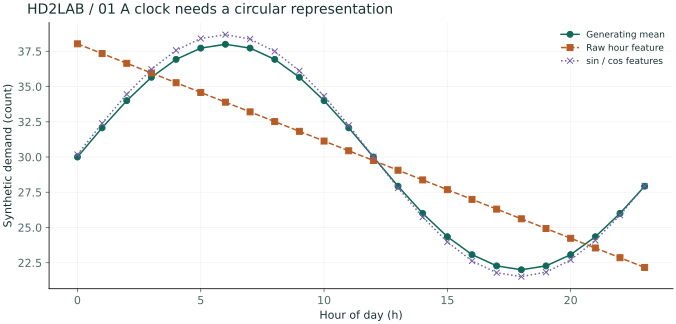

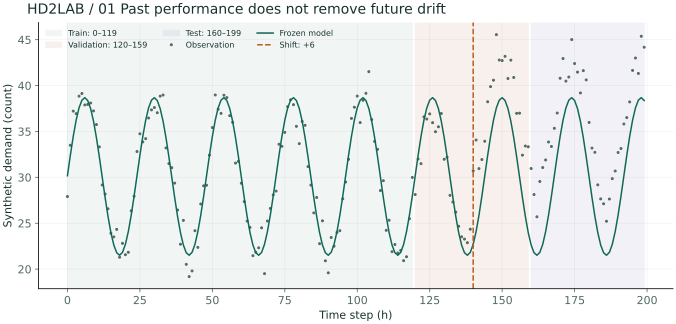

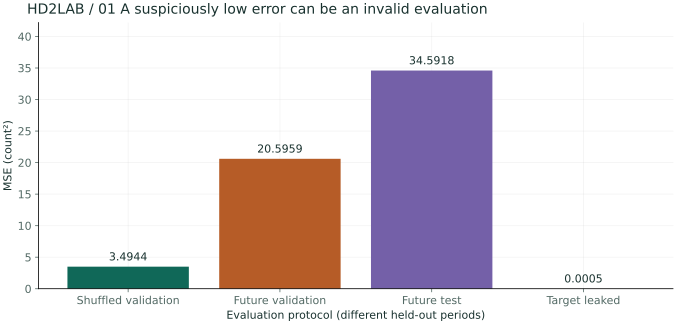

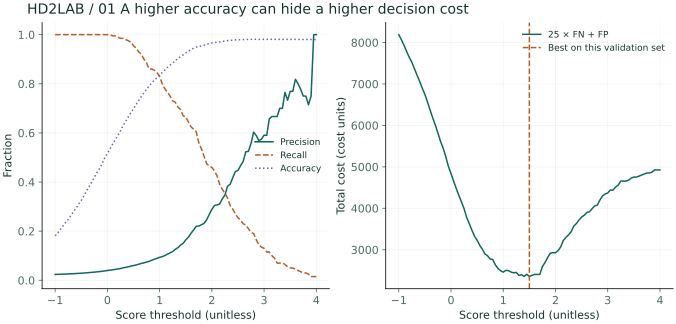

In [3]:
result = EXPERIMENTS[0]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(1, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 02 / 회귀·정규화·불확실성
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "singular": [
    12.459827654292118,
    0.09256485252282366
  ],
  "coefficient_sd": [
    [
      0.4174738196227611,
      0.41616833276326703
    ],
    [
      0.004153270916558123,
      0.003946780212431789
    ]
  ],
  "sum_sd": [
    0.006315003329246001,
    0.0055230253309077335
  ],
  "degree": 3,
  "alpha": 0.0,
  "validation": 0.21648071410853015,
  "test": 0.23986533153452105
}


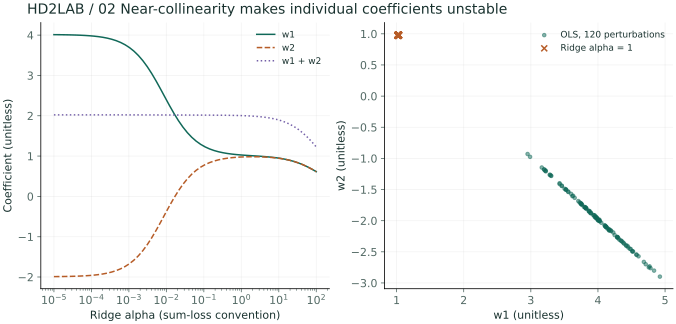

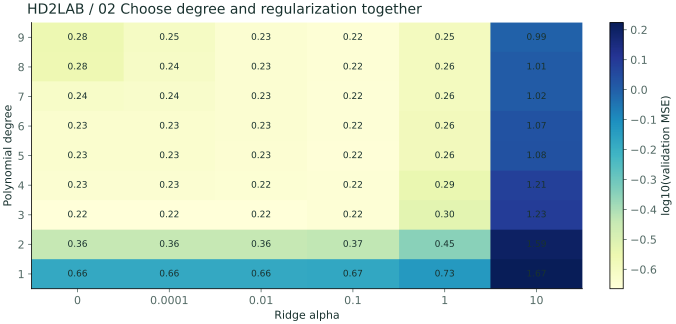

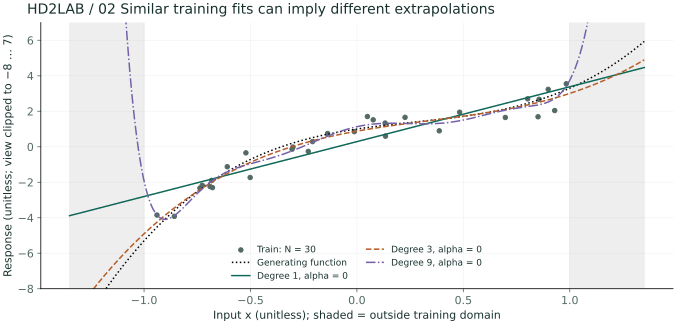

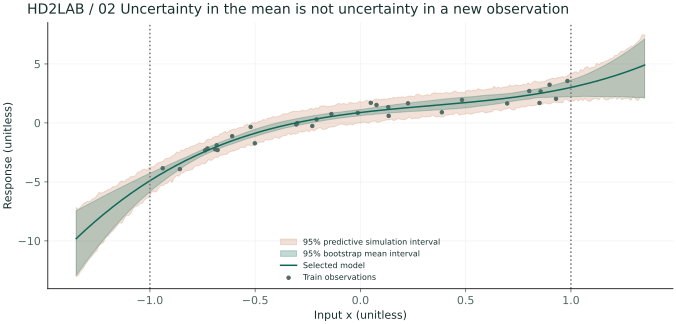

In [4]:
result = EXPERIMENTS[1]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(2, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 03 / 최적화·기울기 검증·SGD
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "final_loss": {
    "GD": 3.928934059906119e-05,
    "Momentum": 4.62645569659164e-15,
    "Newton": 0.0
  },
  "gradient": [
    0.06468020472992608,
    -0.5340808718453713,
    0.2558609049903797
  ],
  "gradient_error": 5.580536033278349e-12,
  "noise_floor": {
    "1": 0.125,
    "16": 0.0078125,
    "64": 0.001953125
  },
  "late_noise": {
    "1": 0.12545188519017866,
    "16": 0.007743766836793791,
    "64": 0.001946974659963864
  }
}


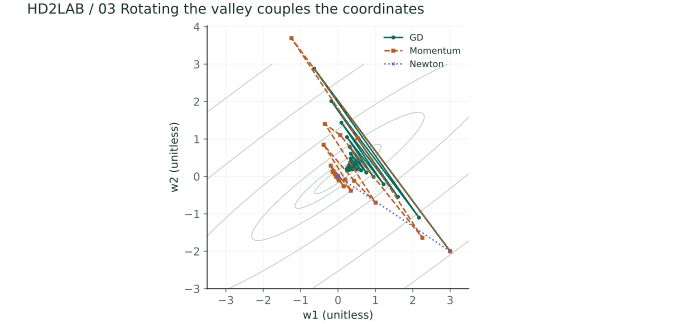

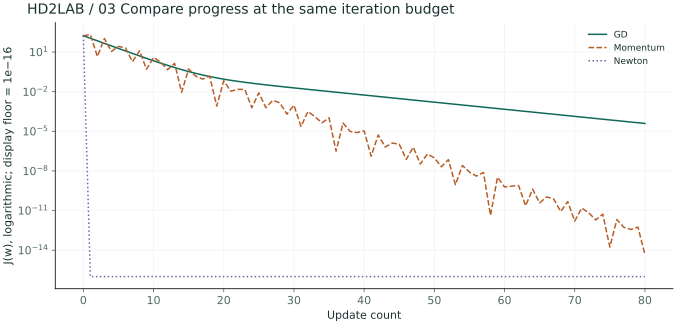

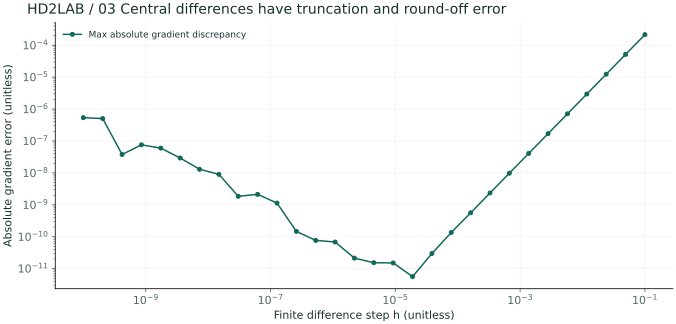

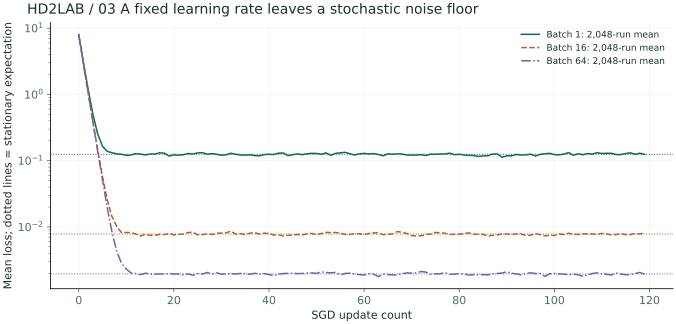

In [5]:
result = EXPERIMENTS[2]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(3, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 04 / 확률·추론·의사결정
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "beta_means": [
    0.1,
    0.1,
    0.09166666666666666
  ],
  "intervals": [
    [
      0.013012326891720074,
      0.2602808946641222
    ],
    [
      0.028659232614611115,
      0.20870223404161176
    ],
    [
      0.0470512128742377,
      0.14911411012992173
    ]
  ],
  "ppv_at_2percent": 0.31468531468531474,
  "action_threshold": 0.038461538461538464,
  "parameter_sd": [
    1.6641005886756874,
    1.2792042981336627,
    0.8571428571428571,
    0.618852747755276,
    0.4423258684646914,
    0.28159395267835924,
    0.1995570315713218,
    0.11538461538461538
  ],
  "predictive_sd": [
    2.6017745423519636,
    2.3741027013091993,
    2.1759351731039738,
    2.093556477242555,
    2.0483291175768223,
    2.0197265047983657,
    2.009931095547695,
    2.0033256374008332
  ]
}


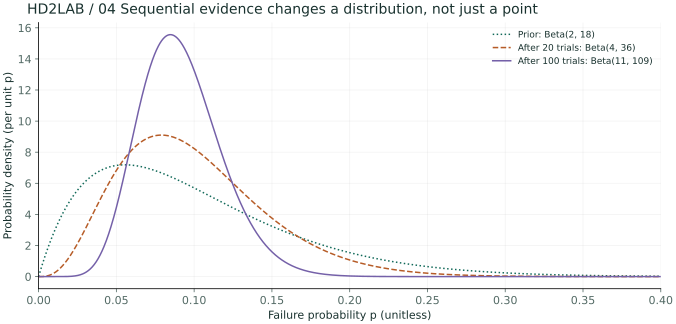

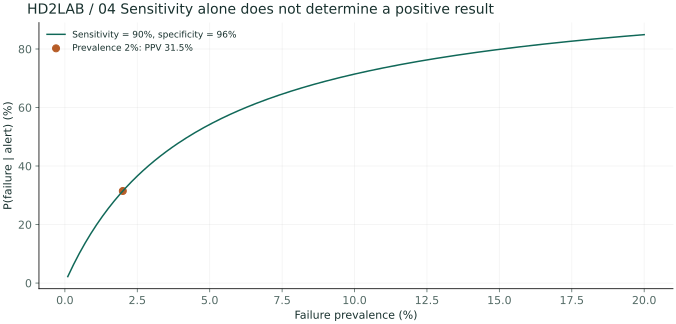

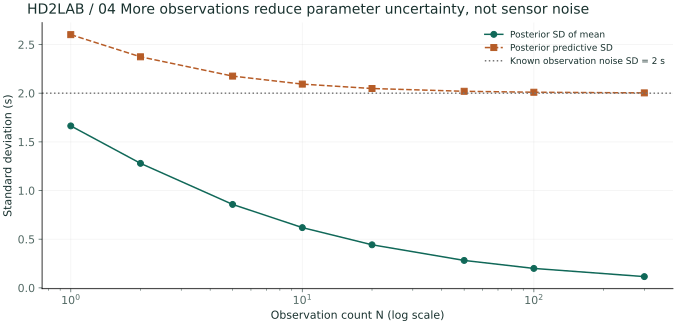

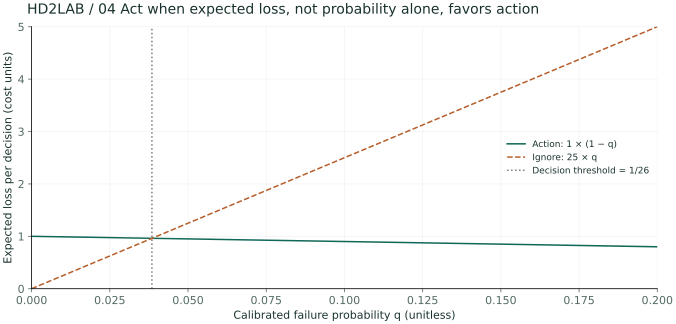

In [6]:
result = EXPERIMENTS[3]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(4, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 05 / PCA·단위·반례
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "eigen": [
    3.651680437657374,
    2.838442128365012,
    0.36405848422411713,
    0.28142788946146263,
    0.25190352189963056,
    0.21777234804552462
  ],
  "errors": [
    [
      7.605284809653121,
      7.273491713464532,
      5.3114829897278835
    ],
    [
      3.9536043719957448,
      4.107254884080073,
      2.8420351187117694
    ],
    [
      1.1151622436307347,
      1.2301743542417336,
      0.6007250514290807
    ],
    [
      0.7511037594066178,
      0.9173877293698486,
      0.8876723421518519
    ],
    [
      0.4696758699451553,
      0.635102046215729,
      1.164547162189251
    ],
    [
      0.21777234804552464,
      0.3477922403128788,
      1.4439488026213467
    ],
    [
      6.543190303629949e-30,
      6.495677511593066e-30,
      1.7680435415216493
    ]
  ],
  "best_clean_k": 2,
  "raw_loading": [
    0.0006379614872722603,
    0.0011906844669703131,
    0.9972898031227428,
    0.0008099454257095632,
    1.2087307363757193e-06,
    7.039676

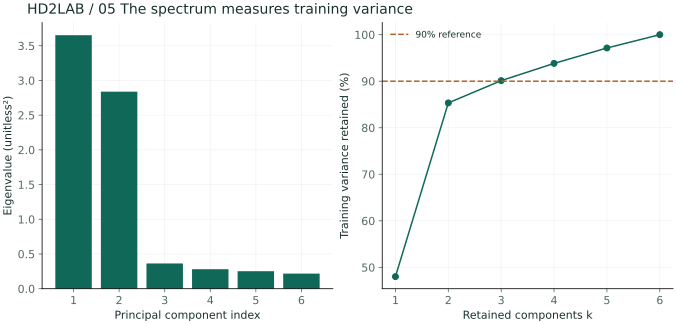

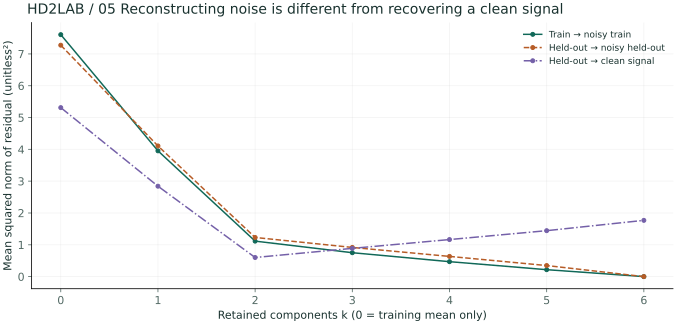

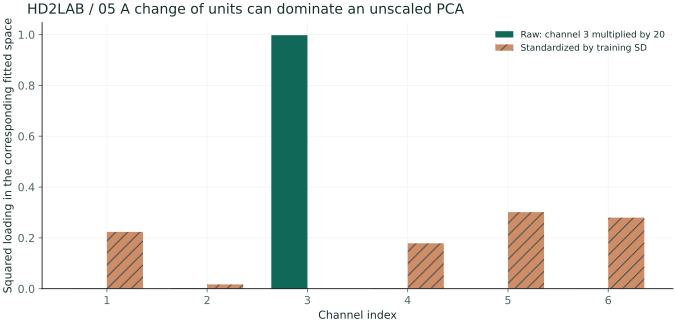

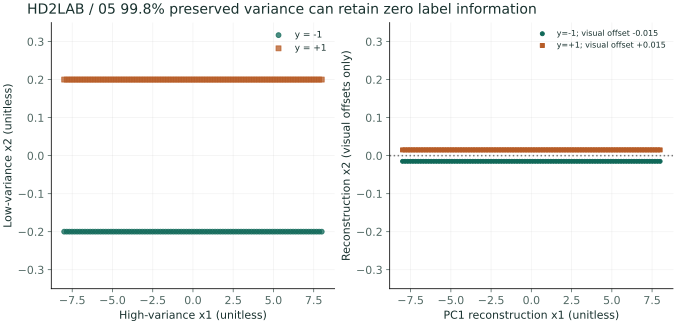

In [7]:
result = EXPERIMENTS[4]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(5, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 06 / GMM·초기화·모델 선택
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "selection": [
    [
      1,
      -610.913783981271,
      1248.5631056161292,
      -2.894810781657026
    ],
    [
      2,
      -575.6098088944688,
      1210.0378006268297,
      -2.817539702687435
    ],
    [
      3,
      -557.4534068507037,
      1205.8076417236043,
      -2.7627512787788975
    ],
    [
      4,
      -553.1810993971312,
      1229.3456720007641,
      -2.8101861711447187
    ],
    [
      5,
      -547.7538180835415,
      1250.5737545578897,
      -2.87433224675154
    ]
  ],
  "bic_k": 3,
  "valid_k": 3,
  "initial_ll": [
    -572.2843750971008,
    -557.4534068507353,
    -557.4534068507037,
    -557.4549129188109
  ],
  "ambiguous": 13,
  "min_cov_eigen": 0.16307883009258803,
  "minimum_ll_step": 1.7053025658242404e-11
}


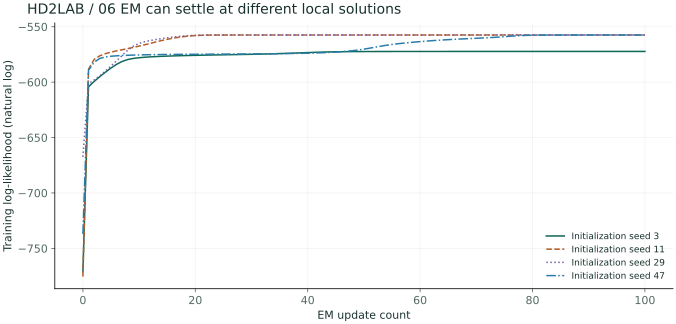

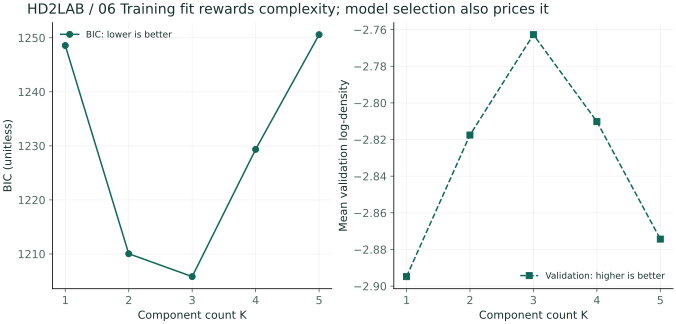

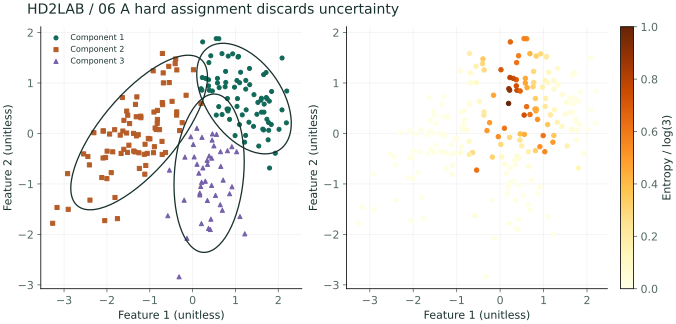

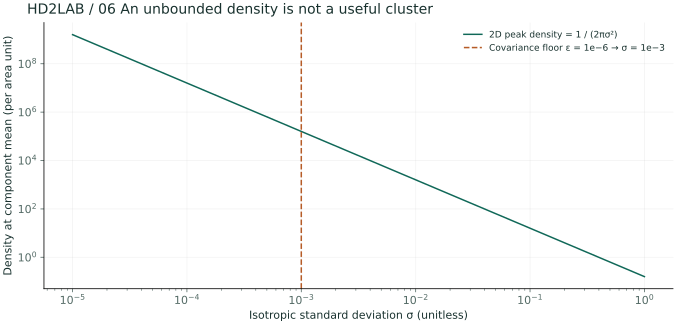

In [8]:
result = EXPERIMENTS[5]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(6, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)


## 07 / SVM·KKT·비선형 특징
결과 JSON의 항목은 웹의 계산 표와 대응합니다. 아래 4개 그림은 사전 계산 출력이며 셀을 실행하면 재생성됩니다.

{
  "comparison": [
    [
      0.03,
      0.972972972972973,
      0.9225,
      32.0,
      -2.220446049250313e-16
    ],
    [
      0.3,
      0.972972972972973,
      0.905,
      14.0,
      1.0709619471786242e-08
    ],
    [
      3.0,
      0.972972972972973,
      0.915,
      8.0,
      3.330300038970437e-08
    ]
  ],
  "xor_linear": 0.5,
  "xor_feature": 1.0,
  "xor_gap": [
    0.0,
    3.048153192256868e-07
  ],
  "free_support": 3,
  "bounded_support": 11
}


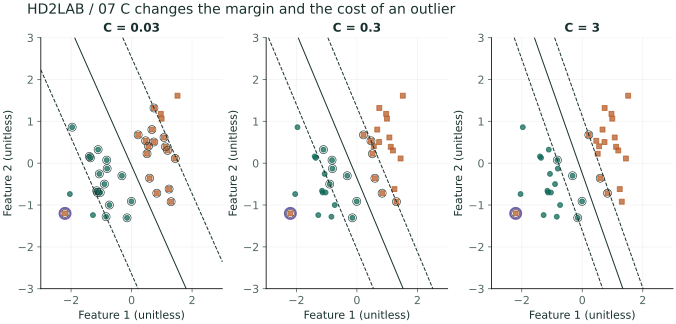

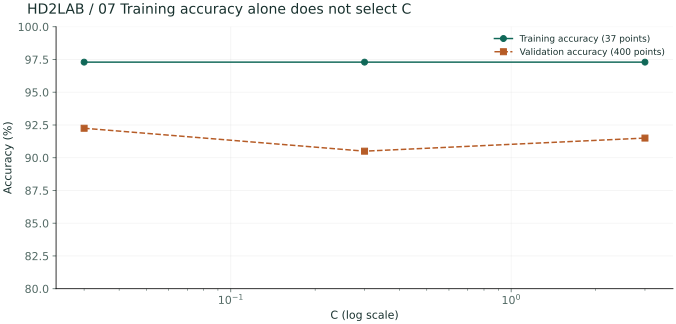

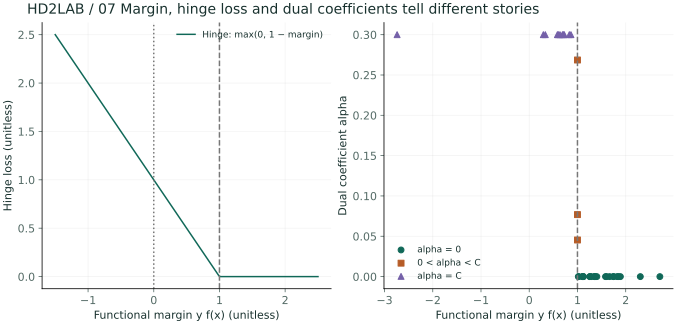

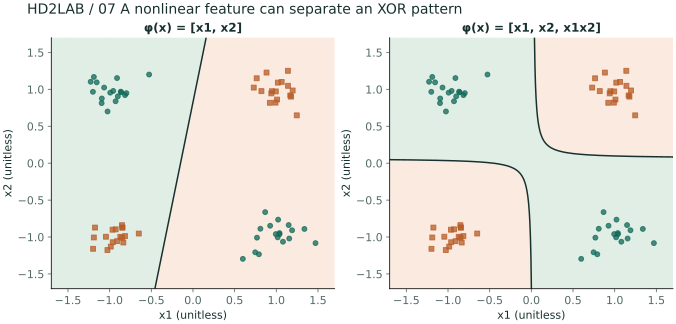

In [9]:
result = EXPERIMENTS[6]()
print(json.dumps(result['summary'], ensure_ascii=False, indent=2))
for name, fig in draw_chapter(7, result):
    buffer = StringIO()
    fig.savefig(buffer, format='svg', metadata={'Date': None, 'Creator': 'HD2Lab / Matplotlib'})
    display(SVG(buffer.getvalue()))
    plt.close(fig)
